# Dashboards: KPIs, filtros e interactividad

El caso conductor es un dashboard ejecutivo de una cadena de supermercados con datos de ventas, satisfacción, clientes y margen por producto y trimestre, para responder preguntas de negocio y diseñar un panel accesible y jerárquico.


## Selección de KPIs relevantes

Los KPIs son métricas específicas que impulsan el negocio y que los analistas observan con atención. Cada industria define sus propios KPIs: para un restaurante puede ser el número de mesas servidas en una noche, para un inversor el retorno de una inversión, para un sitio web de medios los clics en anuncios, y así sucesivamente. La selección de estos indicadores permite enfocar el análisis en los aspectos que realmente inciden en el desempeño del negocio, más allá de otras métricas disponibles.

**Ejemplo:** En el dashboard ejecutivo de la cadena de supermercados, se seleccionan como KPIs la satisfacción del cliente, el margen por producto y el volumen de ventas por trimestre, porque son las métricas que impulsan el negocio y permiten responder las preguntas de negocio planteadas.

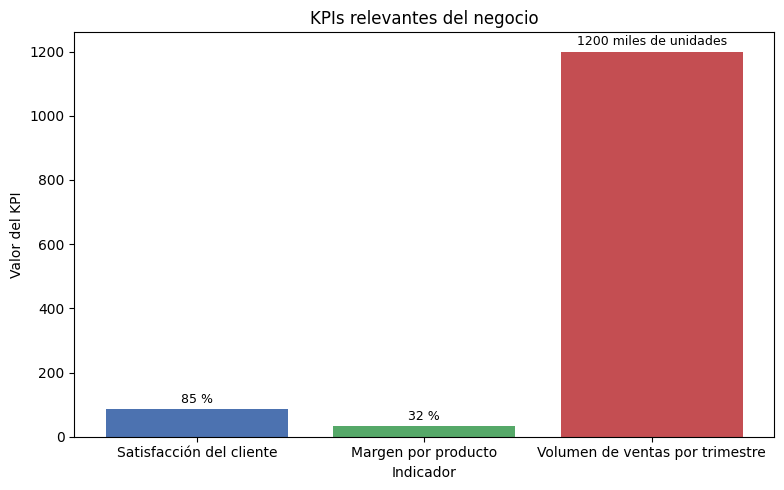

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# KPIs seleccionados para el dashboard ejecutivo de la cadena de supermercados
kpis = pd.DataFrame({
    'KPI': ['Satisfacción del cliente', 'Margen por producto', 'Volumen de ventas por trimestre'],
    'Valor': [85, 32, 1200],
    'Unidad': ['%', '%', 'miles de unidades']
})

# Mostrar la tabla de KPIs seleccionados
print('KPIs seleccionados para el dashboard ejecutivo:')
print(kpis.to_string(index=False))

# Gráfico de barras para visualizar la relevancia de cada KPI
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(kpis['KPI'], kpis['Valor'], color=['#4C72B0', '#55A868', '#C44E52'])
ax.set_title('KPIs relevantes del negocio')
ax.set_ylabel('Valor del KPI')
ax.set_xlabel('Indicador')

# Etiquetar cada barra con su valor y unidad
for i, (valor, unidad) in enumerate(zip(kpis['Valor'], kpis['Unidad'])):
    ax.text(i, valor + 20, f'{valor} {unidad}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## Filtros y segmentación de datos

Los filtros y las segmentaciones permiten restringir los datos que se muestran en una página de informe a valores y rangos específicos. Aunque ambos realizan filtrado de datos, existen diferencias fundamentales: se definen mediante objetos distintos en el diseño del informe. Los filtros actúan sobre los objetos visuales del informe, mientras que las segmentaciones son, en sí mismas, objetos visuales que filtran datos. Los filtros se agregan y configuran desde el panel de filtros, fuera del lienzo del informe. Se pueden establecer filtros básicos y avanzados para restringir datos según distintos campos y valores de medida, pero esta configuración se realiza fuera de la experiencia interactiva de informe. Los filtros pueden aplicarse a todo el informe, a una página del informe o a un objeto visual específico.

**Ejemplo:** Al analizar la satisfacción por trimestre, se agrega una segmentación en la página que permita elegir uno o varios trimestres y actualizar los visuales de satisfacción y margen. Además, se configura un filtro a nivel de página para excluir productos con ventas nulas, y un filtro a nivel de visual para mostrar solo las categorías con margen positivo.

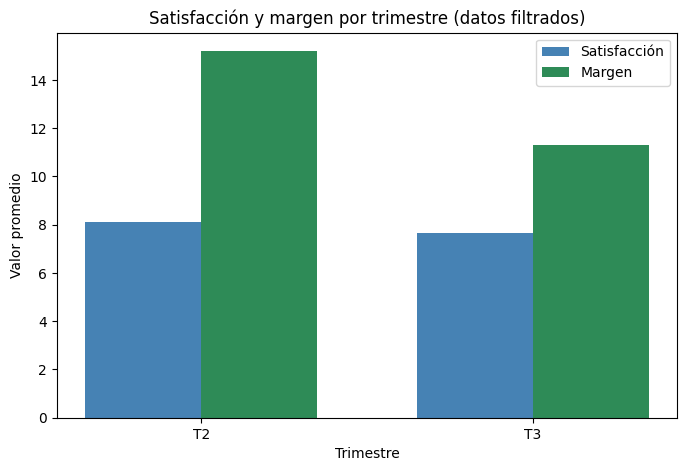

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Datos ilustrativos: satisfacción y margen por trimestre y categoría
datos = pd.DataFrame({
    'trimestre': ['T1', 'T1', 'T2', 'T2', 'T3', 'T3', 'T4', 'T4'],
    'categoria': ['A', 'B', 'A', 'B', 'A', 'B', 'A', 'B'],
    'satisfaccion': [7.5, 6.2, 8.1, 5.8, 8.4, 6.9, 9.0, 7.1],
    'margen': [12.0, -3.5, 15.2, -1.0, 18.4, 4.2, 20.1, 6.5],
    'ventas': [120, 0, 150, 80, 170, 95, 200, 110]
})

# Segmentación: el usuario elige los trimestres a analizar (por ejemplo, T2 y T3)
trimestres_seleccionados = ['T2', 'T3']
datos_segmentados = datos[datos['trimestre'].isin(trimestres_seleccionados)]

# Filtro a nivel de página: excluir productos con ventas nulas
datos_filtrados_pagina = datos_segmentados[datos_segmentados['ventas'] > 0]

# Filtro a nivel de visual: mostrar solo categorías con margen positivo
datos_visual = datos_filtrados_pagina[datos_filtrados_pagina['margen'] > 0]

# Agrupar para graficar satisfacción y margen por trimestre
resumen = datos_visual.groupby('trimestre')[['satisfaccion', 'margen']].mean()

# Gráfico de barras comparando satisfacción y margen por trimestre
x = np.arange(len(resumen.index))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - ancho/2, resumen['satisfaccion'], ancho, label='Satisfacción', color='steelblue')
ax.bar(x + ancho/2, resumen['margen'], ancho, label='Margen', color='seagreen')

ax.set_xticks(x)
ax.set_xticklabels(resumen.index)
ax.set_xlabel('Trimestre')
ax.set_ylabel('Valor promedio')
ax.set_title('Satisfacción y margen por trimestre (datos filtrados)')
ax.legend()

plt.show()

## Interactividad y acciones del panel

La interactividad en un panel permite que el usuario manipule una visualización para modificar la salida de otra. La acción de conectar se emplea para resaltar asociaciones y relaciones entre elementos de datos que ya están representados, y también para mostrar elementos de datos ocultos que son relevantes para un elemento específico. De este modo, la interacción no se limita a una sola vista, sino que coordina múltiples visualizaciones dentro del panel, facilitando la exploración de relaciones y la revelación de información que de otro modo quedaría oculta.

**Ejemplo:** Al hacer clic en la burbuja que representa un producto en el gráfico de dispersión de ventas, se resaltan en el gráfico de barras los trimestres con mayor margen y se muestran los clientes ocultos asociados a ese producto.

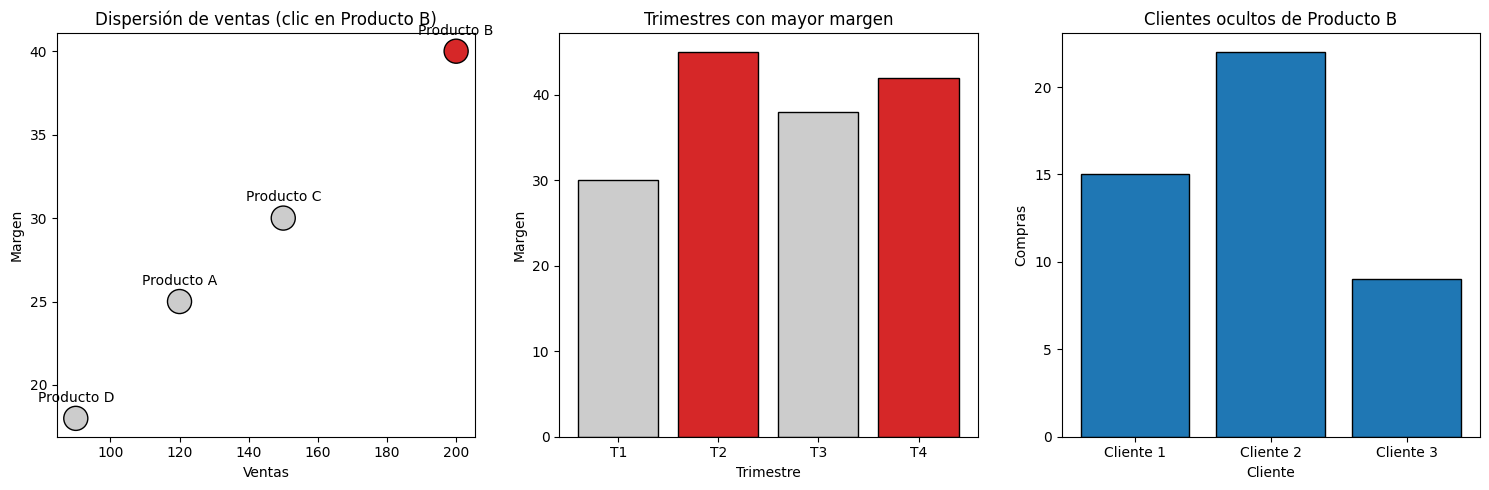

In [ ]:
import matplotlib.pyplot as plt

# Datos de ejemplo: productos con ventas y margen
productos = ['Producto A', 'Producto B', 'Producto C', 'Producto D']
ventas = [120, 200, 150, 90]
margen = [25, 40, 30, 18]

# Producto seleccionado (simula el clic del usuario en la burbuja)
producto_seleccionado = 'Producto B'
indice_sel = productos.index(producto_seleccionado)

# Trimestres con mayor margen asociados al producto seleccionado
trimestres = ['T1', 'T2', 'T3', 'T4']
margen_trimestral = [30, 45, 38, 42]

# Clientes ocultos asociados al producto seleccionado
clientes_ocultos = ['Cliente 1', 'Cliente 2', 'Cliente 3']
compras_clientes = [15, 22, 9]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# Gráfico de dispersión de ventas vs margen por producto
colores = ['#cccccc'] * len(productos)
colores[indice_sel] = '#d62728'
ax1.scatter(ventas, margen, s=300, c=colores, edgecolors='black')
for i, prod in enumerate(productos):
    ax1.annotate(prod, (ventas[i], margen[i]), textcoords='offset points', xytext=(0, 12), ha='center')
ax1.set_xlabel('Ventas')
ax1.set_ylabel('Margen')
ax1.set_title('Dispersión de ventas (clic en ' + producto_seleccionado + ')')

# Gráfico de barras: trimestres con mayor margen resaltados
colores_barras = ['#d62728' if m >= 40 else '#cccccc' for m in margen_trimestral]
ax2.bar(trimestres, margen_trimestral, color=colores_barras, edgecolor='black')
ax2.set_xlabel('Trimestre')
ax2.set_ylabel('Margen')
ax2.set_title('Trimestres con mayor margen')

# Gráfico de barras: clientes ocultos asociados al producto
ax3.bar(clientes_ocultos, compras_clientes, color='#1f77b4', edgecolor='black')
ax3.set_xlabel('Cliente')
ax3.set_ylabel('Compras')
ax3.set_title('Clientes ocultos de ' + producto_seleccionado)

plt.tight_layout()
plt.show()

## Jerarquía visual en el panel

La jerarquía visual en el panel consiste en asignar distinto peso a los elementos según su importancia, de modo que los hallazgos más relevantes reciban atención inmediata. Esto se logra mediante el tamaño, la posición y el énfasis visual de cada componente. Así se establece un orden de lectura lógico que guía al espectador a través de la presentación de datos de manera sistemática, en lugar de permitir patrones de escaneo aleatorios. La jerarquía visual se apoya en estos recursos para que la información prioritaria destaque sobre el resto y el recorrido por el panel sea intencionado.

**Ejemplo:** Al revisar el panel de ventas por trimestre, el margen por producto se ubica en el centro con un tamaño mayor y color intenso, mientras que la satisfacción y el número de clientes se presentan en paneles laterales más pequeños y con tonos suaves, de modo que la atención se dirige primero al margen y luego a los indicadores secundarios.

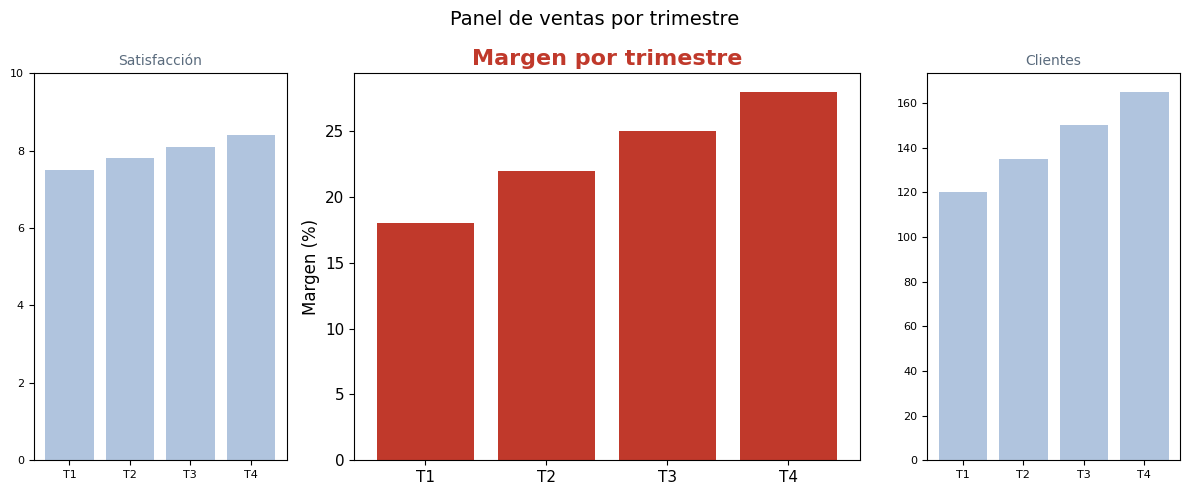

In [ ]:
import matplotlib.pyplot as plt

# Datos ilustrativos del panel de ventas por trimestre
trimestres = ['T1', 'T2', 'T3', 'T4']
margen = [18, 22, 25, 28]
satisfaccion = [7.5, 7.8, 8.1, 8.4]
clientes = [120, 135, 150, 165]

# Creamos una figura con tres paneles: el central mas grande y los laterales mas pequenos
fig = plt.figure(figsize=(12, 5))
grid = fig.add_gridspec(1, 3, width_ratios=[1, 2, 1])

# Panel lateral izquierdo: satisfaccion (secundario, tonos suaves)
ax_izq = fig.add_subplot(grid[0, 0])
ax_izq.bar(trimestres, satisfaccion, color='#b0c4de')
ax_izq.set_title('Satisfacción', fontsize=10, color='#5a6b7d')
ax_izq.set_ylim(0, 10)
ax_izq.tick_params(labelsize=8)

# Panel central: margen por producto (principal, tamano mayor y color intenso)
ax_centro = fig.add_subplot(grid[0, 1])
ax_centro.bar(trimestres, margen, color='#c0392b')
ax_centro.set_title('Margen por trimestre', fontsize=16, fontweight='bold', color='#c0392b')
ax_centro.set_ylabel('Margen (%)', fontsize=12)
ax_centro.tick_params(labelsize=11)

# Panel lateral derecho: numero de clientes (secundario, tonos suaves)
ax_der = fig.add_subplot(grid[0, 2])
ax_der.bar(trimestres, clientes, color='#b0c4de')
ax_der.set_title('Clientes', fontsize=10, color='#5a6b7d')
ax_der.tick_params(labelsize=8)

# Titulo general del panel
fig.suptitle('Panel de ventas por trimestre', fontsize=14)
plt.tight_layout()
plt.show()

## Práctica

Tenés un dashboard de la cadena de supermercados con tres visuales: ventas por trimestre, margen por producto y satisfacción por trimestre. El código actual tiene dos problemas conceptuales: (1) los tres gráficos tienen el mismo tamaño y la misma paleta, así que no hay jerarquía visual y no se sabe cuál es el hallazgo principal; (2) el gráfico de margen por producto muestra todos los productos, incluidos los de margen negativo, cuando el filtro de negocio pide ver solo categorías con margen positivo. Corregí el código para que el margen por producto ocupe el panel central con mayor tamaño y color intenso, y los otros dos queden como paneles laterales más chicos y con tonos suaves. Además, aplicá el filtro de margen positivo en el gráfico de margen. Ejecutá y compará el antes y el después en tu cuaderno de Colab.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Datos ilustrativos del dashboard de la cadena de supermercados
trimestres = ['T1', 'T2', 'T3', 'T4']
ventas = [120, 150, 130, 170]
satisfaccion = [7.8, 8.1, 7.9, 8.4]
productos = ['Lácteos', 'Bebidas', 'Limpieza', 'Snacks', 'Congelados']
margen = [12, -3, 8, 15, -1]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Panel 1: ventas por trimestre
axes[0].bar(trimestres, ventas, color='tab:blue')
axes[0].set_title('Ventas por trimestre')

# Panel 2: margen por producto
# TODO: aplicar el filtro de margen positivo y darle a este panel mayor tamaño y color intenso (jerarquía visual)
axes[1].bar(productos, margen, color='tab:blue')
axes[1].set_title('Margen por producto')

# Panel 3: satisfacción por trimestre
axes[2].plot(trimestres, satisfaccion, marker='o', color='tab:blue')
axes[2].set_title('Satisfacción por trimestre')

plt.tight_layout()
plt.show()